# 01 · Dataset exploration

Inventory, data quality, trajectories, road networks, reference routes and candidate coverage
for the **train** (80) and **student_test** (10) partitions. Evaluator trips are not read here.

Run `scripts/01_inventory.py` and `scripts/02_candidate_sweep.py` first; this notebook reads their outputs.
Figures are written to `results/eda/`, maps to `results/maps/`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathsnap.config import RESULTS_DIR, REPO_ROOT
from pathsnap.io import load_trip, list_trips
from pathsnap.network import build_network, track_xy
from pathsnap.maps import trip_map

pd.set_option("display.width", 200, "display.max_columns", 50)
FIG = RESULTS_DIR / "eda"; FIG.mkdir(parents=True, exist_ok=True)
MAPS = RESULTS_DIR / "maps"; MAPS.mkdir(parents=True, exist_ok=True)
inv = pd.read_csv(FIG / "inventory.csv", dtype={"trip": str})
def save(fig, name): fig.savefig(FIG / name, dpi=130, bbox_inches="tight")

## 1. Inventory

Every trip folder has exactly one `.track`, `.nodes`, `.arcs` and `.route` file named after the trip id.
Each trip carries **its own road network** (a bounding box around the track), so node and arc ids are local to a trip.

In [2]:
files = inv.groupby("partition").agg(
    trips=("trip", "size"),
    obs_total=("n_obs", "sum"),
    obs_median=("n_obs", "median"),
    nodes_median=("n_nodes", "median"),
    arcs_median=("n_arcs", "median"),
    route_arcs_median=("route_len", "median"),
    track_MB=("bytes_track", lambda s: s.sum() / 1e6),
    network_MB=("bytes_nodes", lambda s: s.sum() / 1e6),
)
files

,trips,obs_total,obs_median,nodes_median,arcs_median,route_arcs_median,track_MB,network_MB
partition,,,,,,,,
student_test,10,19160,1420.0,6596.5,13145.0,250.0,0.625911,1.822179
train,80,208417,1529.0,9608.0,19526.5,280.0,6.872352,38.431647


In [3]:
cols = ["n_obs", "duration_s", "path_km", "frac_dt_1s", "dt_max_s", "n_gaps_gt10s",
        "speed_p50_ms", "n_nodes", "n_arcs", "arc_len_p50_m", "route_len", "route_km"]
inv[cols].describe(percentiles=[.1, .5, .9]).T.round(2)

,count,mean,std,min,10%,50%,90%,max
n_obs,90.0,2528.63,3157.00,262.00,593.70,1496.50,4273.70,19313.00
duration_s,90.0,5274.25,17240.02,265.00,779.70,1710.00,7263.70,154030.00
path_km,90.0,36.43,33.41,5.56,8.67,24.05,83.60,169.55
frac_dt_1s,90.0,0.94,0.11,0.53,0.77,0.99,1.00,1.00
dt_max_s,90.0,2408.52,16996.22,1.00,1.00,7.00,314.90,153064.00
n_gaps_gt10s,90.0,6.86,24.97,0.00,0.00,0.00,11.10,215.00
speed_p50_ms,90.0,14.88,7.36,5.64,8.04,12.80,24.33,41.37
n_nodes,90.0,22490.82,30868.53,299.00,1879.10,9305.00,60947.40,155003.00
n_arcs,90.0,45132.72,61920.28,649.00,3770.70,18761.50,125969.50,307392.00
arc_len_p50_m,90.0,30.50,15.34,6.75,16.04,25.14,49.31,85.14


## 2. Data types and missing / invalid values

All four file types are headerless and whitespace-separated. Track and node coordinates parse as float64,
arcs and routes as int64. No trip has missing values, out-of-range coordinates, duplicate rows or non-increasing timestamps.

In [4]:
t = load_trip("00000001", "train")
print({name: df.dtypes.to_dict() for name, df in [("track", t.track), ("nodes", t.nodes), ("arcs", t.arcs)]},
      "route:", t.route.dtype)
inv[["n_missing", "n_out_of_range", "n_duplicate_rows", "n_non_increasing_t", "route_out_of_range",
     "n_isolated_nodes", "n_self_loops", "n_duplicate_arcs", "n_zero_length_arcs"]].agg(["sum", "max"]).T

{'track': {'lon': dtype('float64'), 'lat': dtype('float64'), 't': dtype('float64')}, 'nodes': {'lon': dtype('float64'), 'lat': dtype('float64')}, 'arcs': {'u': dtype('int64'), 'v': dtype('int64')}} route: int64


,sum,max
n_missing,0,0
n_out_of_range,0,0
n_duplicate_rows,0,0
n_non_increasing_t,0,0
route_out_of_range,0,0
n_isolated_nodes,0,0
n_self_loops,24,8
n_duplicate_arcs,1903,322
n_zero_length_arcs,106,14


## 3. Sampling intervals and GPS gaps

Most trips are 1 Hz, but a minority have long gaps. A step longer than 10 s counts as a gap.

steps at 1 s: 96.7%   steps > 10 s: 0.27%   non-integer steps: 12 of 227487


,partition,trip,n_obs,frac_dt_1s,dt_max_s,n_gaps_gt10s,gap_time_frac
82,train,00000090,536,0.581308,153064.0,6,0.994157
71,train,00000078,2909,0.755158,52810.0,25,0.920707
65,train,00000069,2067,0.989351,2658.0,2,0.625045
26,train,00000021,15783,0.999620,2161.0,2,0.151626
18,train,00000011,2828,0.999646,909.0,1,0.243373
44,train,00000042,7739,0.989532,670.0,37,0.368829
74,train,00000081,3224,0.719826,536.0,86,0.441339
28,train,00000024,801,0.971250,458.0,2,0.458793


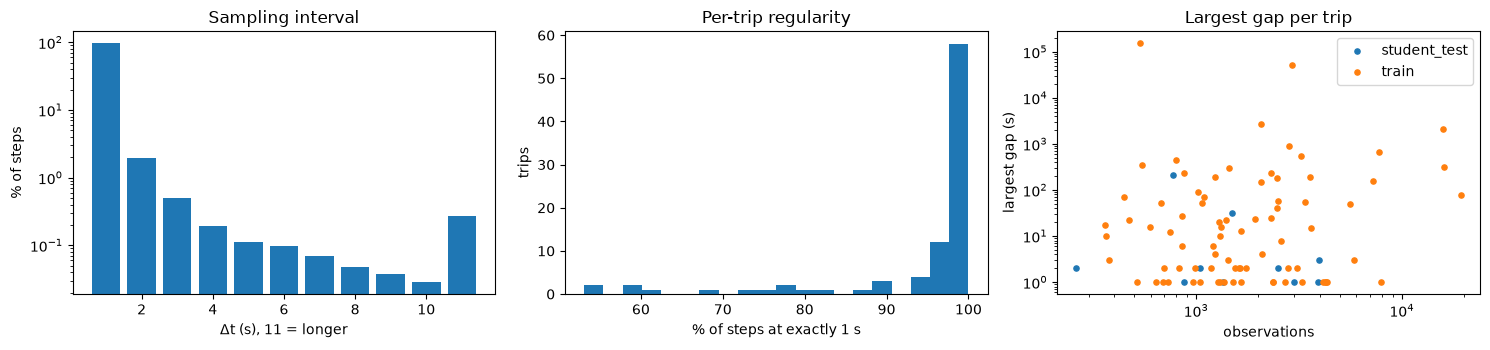

In [5]:
dts = []
for part in ("train", "student_test"):
    for tid in list_trips(part):
        tt = load_trip(tid, part, with_route=False).track.t.to_numpy()
        dts.append(np.diff(tt))
dts = np.concatenate(dts)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
vals, cnt = np.unique(np.clip(np.round(dts), 0, 11), return_counts=True)
axes[0].bar(vals, cnt / cnt.sum() * 100); axes[0].set_yscale("log")
axes[0].set_xlabel("Δt (s), 11 = longer"); axes[0].set_ylabel("% of steps"); axes[0].set_title("Sampling interval")
axes[1].hist(inv["frac_dt_1s"] * 100, bins=20); axes[1].set_xlabel("% of steps at exactly 1 s"); axes[1].set_ylabel("trips")
axes[1].set_title("Per-trip regularity")
for part, d in inv.groupby("partition"):
    axes[2].scatter(d["n_obs"], d["dt_max_s"], s=14, label=part)
axes[2].legend()
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_xlabel("observations"); axes[2].set_ylabel("largest gap (s)")
axes[2].set_title("Largest gap per trip")
fig.tight_layout(); save(fig, "sampling_intervals.png")
print(f"steps at 1 s: {(dts == 1).mean():.1%}   steps > 10 s: {(dts > 10).mean():.2%}   "
      f"non-integer steps: {(np.abs(dts - np.round(dts)) > 1e-6).sum()} of {len(dts)}")
inv.sort_values("dt_max_s", ascending=False)[["partition", "trip", "n_obs", "frac_dt_1s", "dt_max_s", "n_gaps_gt10s", "gap_time_frac"]].head(8)

## 4. Geographical extent and trajectory patterns

UTM zones used: 25


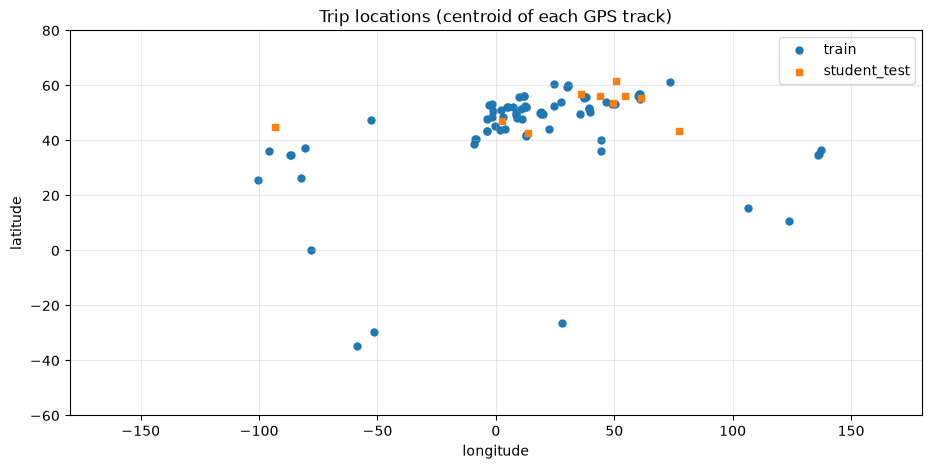

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
for part, mk in [("train", "o"), ("student_test", "s")]:
    d = inv[inv.partition == part]
    ax.scatter((d.lon_min + d.lon_max) / 2, (d.lat_min + d.lat_max) / 2, marker=mk, s=25, label=part)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Trip locations (centroid of each GPS track)"); ax.grid(alpha=.3); ax.legend()
save(fig, "trip_locations.png")
print("UTM zones used:", inv.epsg.nunique())

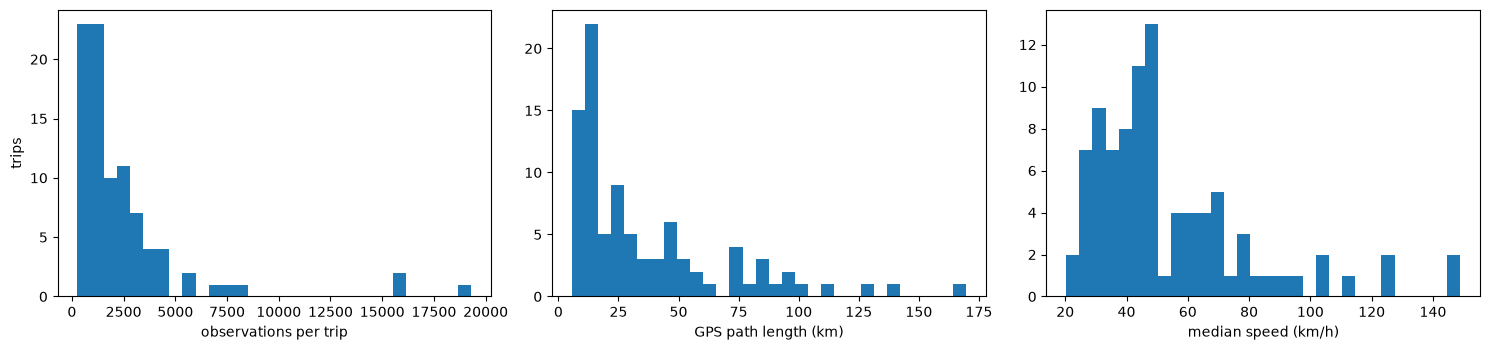

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(inv.n_obs, bins=30); axes[0].set_xlabel("observations per trip"); axes[0].set_ylabel("trips")
axes[1].hist(inv.path_km, bins=30); axes[1].set_xlabel("GPS path length (km)")
axes[2].hist(inv.speed_p50_ms * 3.6, bins=30); axes[2].set_xlabel("median speed (km/h)")
fig.tight_layout(); save(fig, "trajectory_stats.png")

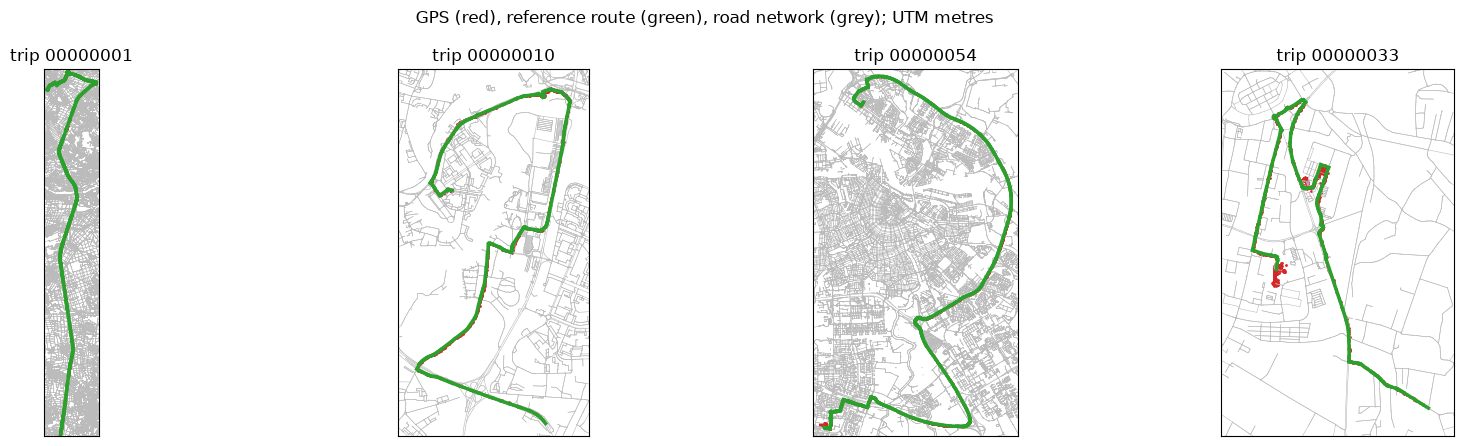

In [8]:
sample = ["00000001", "00000010", "00000054", "00000033"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, tid in zip(axes, sample):
    tr = load_trip(tid, "train"); net = build_network(tr); xy = track_xy(tr, net.epsg) / 1000
    lo, hi = xy.min(0) - .3, xy.max(0) + .3
    a, b = net.a / 1000, net.b / 1000
    keep = ((a >= lo) & (a <= hi)).all(1)
    ax.plot(np.stack([a[keep, 0], b[keep, 0]]), np.stack([a[keep, 1], b[keep, 1]]), color="#bbb", lw=.4)
    ra, rb = net.a[tr.route] / 1000, net.b[tr.route] / 1000
    ax.plot(np.stack([ra[:, 0], rb[:, 0]]), np.stack([ra[:, 1], rb[:, 1]]), color="#2ca02c", lw=2.5)
    ax.scatter(xy[:, 0], xy[:, 1], s=1, color="#d62728")
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_aspect("equal")
    ax.set_title(f"trip {tid}"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("GPS (red), reference route (green), road network (grey); UTM metres"); fig.tight_layout()
save(fig, "trajectory_examples.png")

## 5. Road networks: size and connectivity

Arcs are directed straight segments; most roads appear as two arcs (one per direction).
Weak components ignore direction; strong components respect it and matter for routing in the HMM.

,count,mean,std,min,10%,50%,90%,max
n_nodes,90.0,22490.822,30868.526,299.000,1879.100,9305.000,60947.400,155003.000
n_arcs,90.0,45132.722,61920.285,649.000,3770.700,18761.500,125969.500,307392.000
arc_len_p50_m,90.0,30.503,15.336,6.751,16.041,25.142,49.312,85.138
frac_two_way,90.0,0.922,0.091,0.351,0.824,0.951,0.995,1.000
n_weak_components,90.0,37.200,58.149,1.000,3.000,19.000,84.600,421.000
n_strong_components,90.0,233.467,329.422,2.000,5.900,107.000,562.200,1942.000
frac_nodes_largest_scc,90.0,0.949,0.056,0.636,0.900,0.964,0.987,1.000
route_in_largest_scc,90.0,0.990,0.058,0.467,0.999,1.000,1.000,1.000


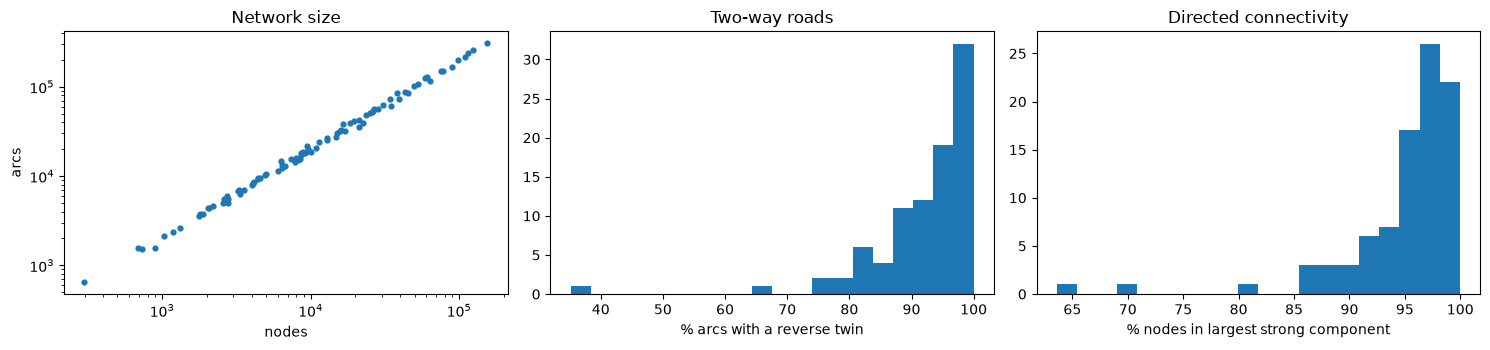

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].scatter(inv.n_nodes, inv.n_arcs, s=12); axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("nodes"); axes[0].set_ylabel("arcs"); axes[0].set_title("Network size")
axes[1].hist(inv.frac_two_way * 100, bins=20); axes[1].set_xlabel("% arcs with a reverse twin"); axes[1].set_title("Two-way roads")
axes[2].hist(inv.frac_nodes_largest_scc * 100, bins=20); axes[2].set_xlabel("% nodes in largest strong component")
axes[2].set_title("Directed connectivity")
fig.tight_layout(); save(fig, "network_stats.png")
inv[["n_nodes", "n_arcs", "arc_len_p50_m", "frac_two_way", "n_weak_components",
     "n_strong_components", "frac_nodes_largest_scc", "route_in_largest_scc"]].describe(percentiles=[.1, .5, .9]).T.round(3)

## 6. Reference routes

The `.route` file lists arc ids in travel order. It does not say which arc each GPS point is on, so we build
per-observation labels with a monotonic alignment (`pathsnap.labels`): each point gets a route position, positions never
decrease, and the total point-to-arc distance is minimised. The distance from a point to its label arc is a direct
measure of GPS noise plus reference-route error.

In [10]:
inv[["route_len", "route_unique_arcs", "route_breaks", "route_km", "route_positions_used",
     "label_dist_p50_m", "label_dist_p95_m", "frac_label_dist_gt50m"]].describe(percentiles=[.1, .5, .9]).T.round(3)

,count,mean,std,min,10%,50%,90%,max
route_len,90.0,386.811,359.238,59.000,130.900,272.500,756.400,2266.000
route_unique_arcs,90.0,383.233,351.894,59.000,130.900,272.500,756.400,2252.000
route_breaks,90.0,0.156,0.472,0.000,0.000,0.000,1.000,3.000
route_km,90.0,27.518,25.167,5.014,6.936,14.314,71.300,94.339
route_positions_used,90.0,0.904,0.071,0.668,0.789,0.923,0.977,1.000
label_dist_p50_m,90.0,7.820,18.794,3.448,4.016,4.675,6.609,140.088
label_dist_p95_m,90.0,23.523,34.825,10.345,12.168,14.482,28.243,242.357
frac_label_dist_gt50m,90.0,0.022,0.113,0.000,0.000,0.000,0.015,0.894


count    227577.00
mean         20.97
std          47.60
min           0.00
50%           5.64
90%          54.80
95%         139.02
99%         203.58
max         647.18
Name: label_dist, dtype: float64


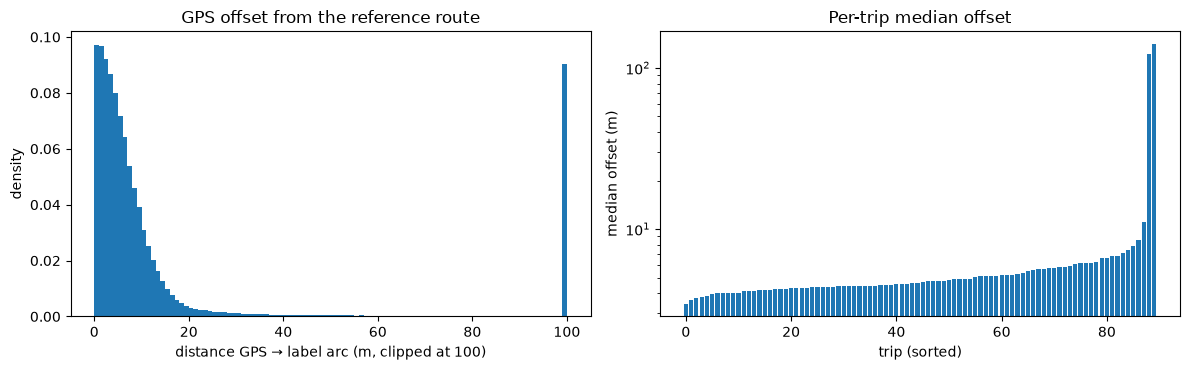

In [11]:
labs = pd.concat([pd.read_parquet(REPO_ROOT / "artifacts" / "labels" / f"{t}.parquet").assign(trip=t, partition=p)
                  for p, t in inv[["partition", "trip"]].itertuples(index=False)])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
d = labs.label_dist.clip(upper=100)
axes[0].hist(d, bins=100, density=True); axes[0].set_xlabel("distance GPS → label arc (m, clipped at 100)")
axes[0].set_ylabel("density"); axes[0].set_title("GPS offset from the reference route")
per = inv.set_index("trip").label_dist_p50_m.sort_values()
axes[1].bar(range(len(per)), per.values); axes[1].set_yscale("log"); axes[1].set_xlabel("trip (sorted)")
axes[1].set_ylabel("median offset (m)"); axes[1].set_title("Per-trip median offset")
fig.tight_layout(); save(fig, "label_offset.png")
print(labs.label_dist.describe(percentiles=[.5, .9, .95, .99]).round(2))

In [12]:
inv.sort_values("frac_label_dist_gt50m", ascending=False)[
    ["partition", "trip", "n_obs", "path_km", "route_km", "label_dist_p50_m", "frac_label_dist_gt50m", "route_breaks"]].head(6)

,partition,trip,n_obs,path_km,route_km,label_dist_p50_m,frac_label_dist_gt50m,route_breaks
54,train,00000054,19313,169.552447,31.418378,140.087585,0.894423,0
36,train,00000033,5844,47.909111,6.385711,122.413239,0.590178,1
11,train,00000002,7243,55.944589,7.973523,5.774628,0.119840,1
63,train,00000066,4325,83.328937,73.024540,6.590083,0.090173,0
45,train,00000043,2322,63.837897,59.301509,11.011641,0.071921,0
74,train,00000081,3224,38.750056,26.169648,4.536955,0.044355,0


## 7. Candidate coverage

The candidate set for an observation is the `k` nearest arcs within `r` metres. The **candidate miss rate** is the share
of observations whose label arc is not in that set, an upper bound on what any classifier or decoder can recover.
The "clean" rate excludes observations more than 50 m from their label arc (see §6).

In [13]:
sweep = pd.read_csv(RESULTS_DIR / "candidates" / "sweep.csv")
show = sweep[sweep.k.isin([8, 16, 32, 10000])].pivot_table(index=["radius", "k"], columns="partition",
        values=["miss_rate", "miss_rate_clean", "mean_candidates"]).round(4)
show

mean_candidates             miss_rate         miss_rate_clean        
partition       student_test    train student_test   train    student_test   train
radius k                                                                          
25     8              4.3518   3.8295       0.0165  0.1351          0.0151  0.0265
       16             4.9850   4.2922       0.0149  0.1328          0.0135  0.0239
       32             5.0936   4.4147       0.0148  0.1321          0.0134  0.0231
       10000          5.1007   4.4392       0.0148  0.1321          0.0134  0.0231
50     8              6.0949   5.3169       0.0038  0.1189          0.0024  0.0082
       16             8.9124   7.3074       0.0017  0.1157          0.0003  0.0046
       32            10.5391   8.5794       0.0014  0.1118          0.0000  0.0002
       10000         10.9145   8.9587       0.0014  0.1116          0.0000  0.0000
75     8              6.7826   6.1112       0.0034  0.1142          0.0024  0.0082
       16            11.2919   9.3794       0.0014  0.1107          0.0003  0.0046
       32            16.1991  12.6455       0.0011  0.1051          0.0000  0.0002
       10000         18.5584  14.8395       0.0011  0.1026          0.0000  0.0000
100    8              7.0836   6.6999       0.0032  0.1109          0.0024  0.0082
       16            12.3193  10.9990       0.0011  0.1071          0.0003  0.0046
       32            20.0364  16.1497       0.0009  0.1013          0.0000  0.0002
       10000         27.7449  22.3612       0.0009  0.0986          0.0000  0.0000
150    8              7.4195   7.5357       0.0031  0.0786          0.0024  0.0082
       16            13.3434  13.1669       0.0007  0.0691          0.0003  0.0046
       32            23.5312  21.6796       0.0002  0.0624          0.0000  0.0002
       10000         51.3732  42.5923       0.0002  0.0446          0.0000  0.0000
200    8              7.5873   7.7624       0.0031  0.0784          0.0024  0.0082
       16            13.9294  14.1411       0.0007  0.0628          0.0003  0.0046
       32            25.1856  24.9693       0.0000  0.0397          0.0000  0.0002
       10000         81.8358  71.1704       0.0000  0.0119          0.0000  0.0000

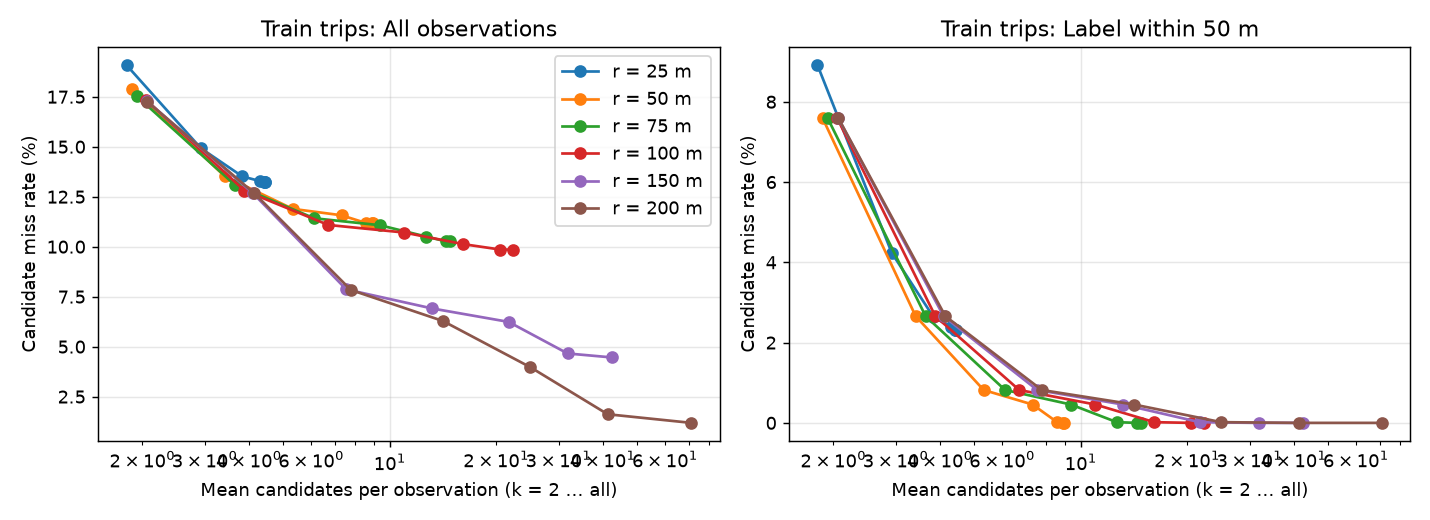

In [14]:
from IPython.display import Image
Image(str(RESULTS_DIR / "candidates" / "sweep.png"))

## 8. Interactive maps

In [15]:
for part, tid in [("train", "00000001"), ("train", "00000054"), ("student_test", "00000052")]:
    tr = load_trip(tid, part); net = build_network(tr)
    trip_map(tr, net, reference=tr.route, gps_every=max(1, tr.n_obs // 2000)).save(MAPS / f"eda_{tid}.html")
sorted(p.name for p in MAPS.glob("eda_*.html"))

['eda_00000001.html', 'eda_00000052.html', 'eda_00000054.html']

## 9. Data-quality issues, assumptions and decisions

| Finding | Evidence | Decision |
|---|---|---|
| Trips span ~25 UTM zones worldwide | §4 | Project each trip to the UTM zone of its GPS centroid; all distances in metres |
| Each trip has its own network; ids are trip-local | §1 | Load the network per trip in training, decoding and the API |
| No missing values, invalid coordinates or out-of-order timestamps | §2 | No row dropping needed |
| Most steps are 1 s, but a few trips have very long gaps (up to ~42 h in trip 90) | §3 | Use Δt as a feature and in HMM transitions; break or relax transitions across large gaps |
| ~92 % of arcs have a reverse twin with the same geometry | §5 | Heading/travel direction features are needed to separate the two directions |
| Networks contain many small strong components | §5 | Decoder must survive unreachable transitions (fallback / restart) |
| Reference route has occasional breaks (non-adjacent consecutive arcs) | §6 | Treat as reference, not perfect truth; report it |
| 12 of ~227k time steps are non-integer (trips 2, 71, 97) | §3 | Keep timestamps as float seconds |
| Labels are not per-observation | §6 | Monotonic alignment of points to route positions |
| Trips 33 and 54: most GPS is > 50 m from the reference route (long stretches in areas with no mapped roads) | §6, map `eda_00000054.html` | Exclude observations > 50 m from their label from training; report metrics with and without them |
| ~10 % of route arcs get no GPS point (short arcs passed within 1 s) | §6 | Observation-level metrics ignore them; sequence-level metrics include them |